# Stage 3: Baseline models

This notebook builds and evaluates the baseline models for the probability that a shot is made.
They are the reference point for the main model in Stage 4 (gradient boosting).

- **Null model:** every shot gets the league FG% of the training seasons.
- **Zone baseline:** every shot gets the historical FG% of its court zone
  (`SHOT_ZONE_BASIC` x `SHOT_ZONE_AREA`), the simplest possible xPTS.
- **Logistic regression:** B-splines of the exact shot distance, their interactions with the shot type
  (`action_group`) and a few binary flags.

Expected points follow from the probability: xPTS = P(made) x `shot_value`.

**Validation: walk-forward with an expanding window.** For every season S the model is trained on
all seasons before S and predicts S (train 2014-15 ... S-1, test S). No model ever sees a shot from
its own test season or from the future, and every shot gets an out-of-sample prediction.
Anything fitted on data (zone averages, spline knots, coefficients) is fitted inside each fold
on the training seasons only.

**Hold-out.** Season 2025-26 is removed right after loading. It is the final test set and is used
once, at the end of the project, so no modelling decision here is based on it.

**Metrics** (`xpts.metrics`): log loss (main metric), Brier score, AUC and calibration
(mean predicted probability vs observed FG% in bins).

## 0. Setup

Imports, paths and the data. The shared code lives in the `xpts` package (`src/xpts/`):
`validation.walk_forward` gives the folds, `metrics` the scores, `baselines.ZoneBaseline` the zone model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from xpts.baselines import ZoneBaseline
from xpts.metrics import calibration_table, evaluate
from xpts.validation import HOLDOUT_SEASON, walk_forward

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
df = pd.read_parquet("../data/processed/shots_features.parquet")
df = df[df["SEASON"] != HOLDOUT_SEASON].reset_index(drop=True)  # hold-out season, never used here
y = df["SHOT_MADE_FLAG"]

print(f"shots: {len(df):,}, columns: {df.shape[1]}")
print(f"seasons: {df['SEASON'].min()} to {df['SEASON'].max()}")
print(f"FG%: {y.mean():.3f}")

shots: 2,305,805, columns: 25
seasons: 2014-15 to 2024-25
FG%: 0.462


**Shots and FG% per season.** Each row is one test season of the walk-forward; the training window
grows by one season per fold (2015-16 is trained on 2014-15 only, 2024-25 on ten seasons).

In [3]:
df.groupby("SEASON").agg(shots=("SHOT_MADE_FLAG", "size"), fg=("SHOT_MADE_FLAG", "mean")).round(3)

,shots,fg
SEASON,,
2014-15,205550,0.449
2015-16,207893,0.452
2016-17,209929,0.457
2017-18,211707,0.460
2018-19,219458,0.461
2019-20,188116,0.460
2020-21,190983,0.466
2021-22,216722,0.461
2022-23,217220,0.475


## 1. Null model

Every test shot gets the same probability: the league FG% of the training seasons.
It uses no information about the shot, so it is the lower bar that every real model has to beat.
A constant prediction cannot rank shots, so its AUC is 0.5 by definition.

The out-of-sample predictions of every model are stored in `oos` (one column per model),
so that all models can be compared on exactly the same shots.

In [4]:
oos = pd.DataFrame({"SEASON": df["SEASON"], "y": y})
rows = []
for season, tr, te in walk_forward(df["SEASON"]):
    p = np.full(te.sum(), y[tr].mean())  # the same probability for every test shot
    oos.loc[te, "null"] = p
    rows.append({"model": "null", "season": season, **evaluate(y[te], p)})

results = pd.DataFrame(rows)
results.round(4)

,model,season,n,log_loss,brier,auc
0,null,2015-16,207893,0.6886,0.2477,0.5
1,null,2016-17,209929,0.6896,0.2482,0.5
2,null,2017-18,211707,0.6901,0.2485,0.5
3,null,2018-19,219458,0.6901,0.2485,0.5
4,null,2019-20,188116,0.6900,0.2484,0.5
5,null,2020-21,190983,0.6910,0.2489,0.5
6,null,2021-22,216722,0.6901,0.2485,0.5
7,null,2022-23,217220,0.6925,0.2497,0.5
8,null,2023-24,218700,0.6922,0.2495,0.5
9,null,2024-25,219527,0.6911,0.2490,0.5


## 2. Zone baseline

**Zones.** Every shot in nba_api comes with two official zone labels assigned by the NBA from the shot
location (they are not built by us): `SHOT_ZONE_BASIC`, the type of area (Restricted Area, In The Paint (Non-RA),
Mid-Range, Left / Right Corner 3, Above the Break 3, Backcourt), and `SHOT_ZONE_AREA`, the side of the court
(Left Side, Left Side Center, Center, ...). Their combination gives 16 zones that occur in the data.

**Model.** `ZoneBaseline` (in `src/xpts/baselines.py`) predicts for each shot the FG% of its zone, computed
on the training seasons only:

- `fit` counts makes $k$ and attempts $n$ per zone in the training seasons and the league FG% $p_{league}$;
- `predict_proba` looks up the zone of each test shot; a zone never seen in training gets $p_{league}$.

**Smoothing (shrinkage).** The raw zone FG% $k / n$ is noisy when $n$ is small. Instead we use

$$\hat p_{zone} = \frac{k + \alpha \, p_{league}}{n + \alpha}, \qquad \alpha = 20,$$

which is the same as adding $\alpha$ virtual shots made at the league rate to every zone.
It can be rewritten as a weighted average of the zone and the league:

$$\hat p_{zone} = w \, \frac{k}{n} + (1 - w) \, p_{league}, \qquad w = \frac{n}{n + \alpha}.$$

With few shots ($n \ll \alpha$) the estimate stays close to the league FG%; with many shots ($n \gg \alpha$) it
equals the zone FG%. Examples with $p_{league} = 0.46$: 1 make in 10 shots gives 0.34 instead of 0.10;
40 makes in 500 gives 0.095 instead of 0.080; for the Restricted Area (hundreds of thousands of shots) nothing changes.

**Bayesian interpretation.** Before seeing a zone's shots, our belief about its true FG% $p$ is a
*prior* distribution $p \sim \mathrm{Beta}(a, b)$ with mean $a / (a + b) = p_{league}$ and strength
$a + b = \alpha$ (it is worth $\alpha$ shots of evidence). The makes in the zone follow a binomial distribution,
$k \sim \mathrm{Binomial}(n, p)$. Beta is conjugate to the binomial, so the *posterior* after seeing the data is
$\mathrm{Beta}(a + k, \, b + n - k)$, and its mean is exactly $\hat p_{zone}$ above. This prior plus likelihood pair is
the beta-binomial model; the same shrinkage is used in Stage 5 for players, where sample sizes really are small.

Here the smoothing is only a safeguard: the smallest zone (Back Court beyond the arc) has a few hundred shots,
so $\alpha = 20$ is fixed and not tuned.

In [5]:
rows = []
for season, tr, te in walk_forward(df["SEASON"]):
    model = ZoneBaseline().fit(df[tr], y[tr])
    p = model.predict_proba(df[te])[:, 1]
    oos.loc[te, "zone"] = p
    rows.append({"model": "zone", "season": season, **evaluate(y[te], p)})

results = pd.concat([results, pd.DataFrame(rows)], ignore_index=True)
results[results["model"] == "zone"].round(4)

,model,season,n,log_loss,brier,auc
10,zone,2015-16,207893,0.6652,0.2363,0.6099
11,zone,2016-17,209929,0.6652,0.2363,0.6130
12,zone,2017-18,211707,0.6615,0.2345,0.6201
13,zone,2018-19,219458,0.6602,0.2338,0.6251
14,zone,2019-20,188116,0.6591,0.2333,0.6261
15,zone,2020-21,190983,0.6630,0.2352,0.6225
16,zone,2021-22,216722,0.6577,0.2327,0.6325
17,zone,2022-23,217220,0.6591,0.2333,0.6361
18,zone,2023-24,218700,0.6600,0.2338,0.6321
19,zone,2024-25,219527,0.6584,0.2330,0.6332


**Zone table of the last fold** (trained on 2014-15 to 2023-24). `model` is the zone model from the last
iteration of the loop above, and `model.table_` is what `fit` learned: one smoothed FG% per zone
(a pandas Series indexed by the two zone columns). These 16 numbers are the whole model; every test shot
in a zone gets the same probability.

In [6]:
model.table_.rename("p_zone").round(3).to_frame()

p_zone
SHOT_ZONE_BASIC       SHOT_ZONE_AREA               
Above the Break 3     Back Court(BC)          0.088
                      Center(C)               0.348
                      Left Side Center(LC)    0.354
                      Right Side Center(RC)   0.354
Backcourt             Back Court(BC)          0.025
In The Paint (Non-RA) Center(C)               0.417
                      Left Side(L)            0.418
                      Right Side(R)           0.419
Left Corner 3         Left Side(L)            0.386
Mid-Range             Center(C)               0.417
                      Left Side Center(LC)    0.400
                      Left Side(L)            0.401
                      Right Side Center(RC)   0.399
                      Right Side(R)           0.405
Restricted Area       Center(C)               0.633
Right Corner 3        Right Side(R)           0.387

## 3. Comparison so far

Mean of the per-season metrics (each of the 10 test seasons has the same weight)
and the metrics on all out-of-sample shots pooled together.
The first season (2014-15) is only used for training and has no out-of-sample prediction, so it is dropped from `oos`.

In [7]:
oos = oos.dropna(subset=["null"])  # 2014-15 is only ever a training season
per_season = results.groupby("model")[["log_loss", "brier", "auc"]].mean()
pooled = pd.DataFrame({m: evaluate(oos["y"], oos[m]) for m in ["null", "zone"]}).T
pd.concat({"mean over seasons": per_season, "pooled": pooled[["log_loss", "brier", "auc"]]}, axis=1).round(4)

mean over seasons                   pooled                
              log_loss   brier     auc log_loss   brier     auc
null            0.6905  0.2487  0.5000   0.6905  0.2487  0.5068
zone            0.6610  0.2342  0.6251   0.6609  0.2342  0.6280

**Observations.**
- The null model's log loss (0.6905) is the entropy of a coin with p = 0.46: the score of knowing nothing about the shot.
- Knowing only the zone lowers the log loss to 0.661 and the Brier score from 0.249 to 0.234.
- AUC 0.625: for a random made shot and a random missed shot, the zone model gives the made one a higher
  probability 62.5% of the time (0.5 = guessing). It rises from 0.610 (2015-16) to 0.633 (2024-25) as the shot
  mix becomes more polarised between the rim and the arc.
- The mean over seasons and the pooled score are almost equal, so no single season dominates.
- The pooled AUC of the null model is 0.507, not 0.5, because its constant differs slightly between seasons.

## 4. Calibration of the zone baseline

All out-of-sample predictions pooled, 20 quantile bins of the predicted probability.
A well calibrated model lies on the diagonal: shots with a predicted 40% chance are made about 40% of the time.
The zone model has only 16 distinct values, so many bins collapse into one point.

    p_mean  y_mean       n
0    0.330   0.338  110988
1    0.348   0.349   99071
2    0.350   0.352  118721
3    0.352   0.359  111132
4    0.353   0.357   95526
5    0.368   0.367  100174
6    0.386   0.388  100352
7    0.391   0.394  115626
8    0.396   0.408   94256
9    0.400   0.402  130481
10   0.402   0.410  105224
11   0.405   0.421   84923
12   0.411   0.433  126501
13   0.513   0.525  128917
14   0.602   0.611   67289
15   0.608   0.630  139302
16   0.615   0.635   60503
17   0.620   0.647  120427
18   0.627   0.665  129652
19   0.633   0.664   61190


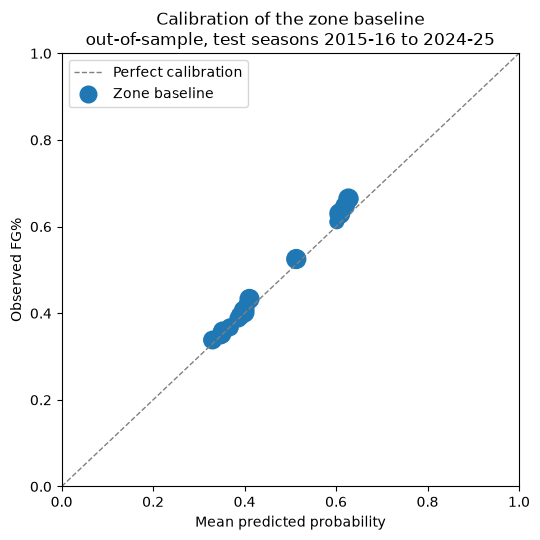

In [8]:
cal = calibration_table(oos["y"], oos["zone"])
print(cal.round(3).to_string())

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Perfect calibration")
ax.scatter(cal["p_mean"], cal["y_mean"], s=cal["n"] / cal["n"].max() * 200, label="Zone baseline")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed FG%")
ax.set_title("Calibration of the zone baseline\nout-of-sample, test seasons 2015-16 to 2024-25")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_calibration_zone.pdf")
plt.show()

**Where is the zone baseline biased?** Mean predicted probability vs observed FG% by test season and by zone
(`diff` = observed − predicted; positive means the model is too pessimistic).

In [9]:
def bias(g):
    return pd.Series({"p_mean": g["zone"].mean(), "y_mean": g["y"].mean()})

zone_basic = df.loc[oos.index, "SHOT_ZONE_BASIC"]
by_season = oos.groupby("SEASON").apply(bias).assign(diff=lambda t: t["y_mean"] - t["p_mean"])
by_zone = oos.groupby(zone_basic).apply(bias).assign(diff=lambda t: t["y_mean"] - t["p_mean"])
display(by_season.round(3), by_zone.round(3))

,p_mean,y_mean,diff
SEASON,,,
2015-16,0.449,0.452,0.003
2016-17,0.448,0.457,0.009
2017-18,0.449,0.460,0.011
2018-19,0.454,0.461,0.006
2019-20,0.453,0.460,0.007
2020-21,0.449,0.466,0.017
2021-22,0.449,0.461,0.012
2022-23,0.453,0.475,0.022
2023-24,0.455,0.474,0.020


,p_mean,y_mean,diff
SHOT_ZONE_BASIC,,,
Above the Break 3,0.349,0.353,0.004
Backcourt,0.031,0.023,-0.008
In The Paint (Non-RA),0.405,0.422,0.017
Left Corner 3,0.383,0.387,0.003
Mid-Range,0.400,0.407,0.007
Restricted Area,0.616,0.639,0.023
Right Corner 3,0.388,0.387,-0.001


**Observations.**
- The predictions are close to the diagonal but **systematically too low**, most of all for the most likely shots:
  in the top bins the model predicts about 0.63 and 66% of the shots go in.
- The gap grows with time: +0.3 pp in 2015-16, about +2 pp from 2022-23 on.
- It comes from shots near the hoop: Restricted Area +2.3 pp, paint +1.7 pp, while 3PT zones are within ±0.4 pp.
- Cause: the league changes (2PT FG% rose from 48.5% to 54.5%, Stage 2), but the expanding window averages
  all past seasons with equal weight, so the model lags behind. To test with the logistic regression:
  a season trend feature or a shorter (sliding) training window.

## 5. Logistic regression with distance splines

Stage 2 showed that FG% depends on distance in a strongly non-linear way and that the shape differs by shot type
(a layup gets much worse with every foot, a jumper hardly changes between 4 and 20 ft).
A logistic regression with a plain linear `dist_ft` term cannot represent this, so the model is

$$\operatorname{logit} P(\text{made}) = \sum_{g} \mathbb{1}[\text{group} = g] \sum_{j} \beta_{g j} B_j(\text{dist}) + \gamma^\top \text{flags},$$

where $B_j$ are cubic B-splines of the distance and $g$ runs over the 10 `action_group` values
(`ShotFeatures` and `make_logit` in `src/xpts/baselines.py`):

- **B-splines** split the distance axis at knots (0, 1, 2, 3, 5, 8, 12, 16, 20, 22, 24, 26, 30, 40 ft) and build smooth
  bump-shaped basis functions between them; a weighted sum of them can follow any smooth curve.
  The knots are dense near the rim and around the 3PT line (22 / 23.75 ft) and are fixed by court geometry,
  not fitted on outcomes. Distances beyond 40 ft (heaves) are clipped to 40 ft.
- **Spline x action_group:** every shot type gets its own distance curve (and its own intercept),
  i.e. 10 x 16 = 160 columns. The matrix is sparse: each shot has at most 4 non-zero spline values.
- **Flags:** `is_three` (jump at the 3PT line), `is_corner3`, `is_heave`, `is_overtime` and
  `last_second` = `secs_left_period <= 1` (Stage 2: shots at the buzzer are worse at every distance).
- **L2 penalty** with C = 1. With 0.2-2 million training shots it hardly matters; it only keeps the
  coefficients of rare combinations (e.g. 30 ft dunks) finite.

Like the zone model, the whole pipeline (spline basis, groups, coefficients) is fitted inside each fold on the
training seasons only.

In [10]:
from xpts.baselines import make_logit

rows = []
for season, tr, te in walk_forward(df["SEASON"]):
    model = make_logit().fit(df[tr], y[tr])
    te_idx = df.index[te]
    p = model.predict_proba(df[te])[:, 1]
    oos.loc[te_idx.intersection(oos.index), "logit"] = p
    rows.append({"model": "logit", "season": season, **evaluate(y[te], p)})

results = pd.concat([results, pd.DataFrame(rows)], ignore_index=True)
results[results["model"] == "logit"].round(4)

,model,season,n,log_loss,brier,auc
20,logit,2015-16,207893,0.6367,0.2238,0.6678
21,logit,2016-17,209929,0.6388,0.2248,0.6634
22,logit,2017-18,211707,0.6493,0.2294,0.6446
23,logit,2018-19,219458,0.6400,0.2255,0.6569
24,logit,2019-20,188116,0.6386,0.2248,0.6568
25,logit,2020-21,190983,0.6458,0.2281,0.6452
26,logit,2021-22,216722,0.6420,0.2263,0.6479
27,logit,2022-23,217220,0.6432,0.2270,0.6521
28,logit,2023-24,218700,0.6437,0.2272,0.6483
29,logit,2024-25,219527,0.6433,0.2269,0.6463


### 5a. What the spline features look like

A look inside the last fitted model (`model`, the 2024-25 fold, trained on 2014-15 to 2023-24) on five real shots
from 2024-25. Three things are kept apart:

- **knots**: fixed places on the distance axis, they only decide where the basis functions sit;
- **basis values $B_j(d)$**: numbers between 0 and 1 computed from the shot distance by a fixed formula, before
  any training and without looking at the outcome;
- **weights $\beta$, $\gamma$**: the coefficients learned by the logistic regression.

**Step 1: the raw shots.**

In [11]:
features, logit = model.named_steps["features"], model.named_steps["logit"]
season_te = df["SEASON"] == "2024-25"
cases = [("layup", 2.9, 3.1), ("jumper", 2.9, 3.1), ("jumper", 14.9, 15.1), ("pullup_jumper", 24.9, 25.1), ("dunk", 0.9, 1.1)]
ex = pd.concat([df[season_te & (df["action_group"] == g) & df["dist_ft"].between(lo, hi) & (df["is_heave"] == 0)
                   & (df["secs_left_period"] > 1)].head(1) for g, lo, hi in cases])
ex.index = [f"shot {i + 1}" for i in range(len(ex))]
ex[["action_group", "dist_ft", "is_three", "is_corner3", "is_heave", "is_overtime", "secs_left_period", "SHOT_MADE_FLAG"]].round(2)

,action_group,dist_ft,is_three,is_corner3,is_heave,is_overtime,secs_left_period,SHOT_MADE_FLAG
shot 1,layup,2.97,0,0,0,0,193,1
shot 2,jumper,3.02,0,0,0,0,271,1
shot 3,jumper,14.90,0,0,0,0,556,1
shot 4,pullup_jumper,25.02,1,0,0,0,336,0
shot 5,dunk,1.08,0,0,0,0,579,1


**Step 2: distance → 16 basis values.** Only the distance goes in. Every row sums to 1 and has at most 4 non-zero values.
Shots 1 and 2 have the same distance, so they get exactly the same B values; the shot type does not enter here.

In [12]:
B = pd.DataFrame(features.spline_.transform(features._dist(ex)).toarray(), index=ex.index,
                 columns=[f"B{j + 1}" for j in range(features.n_basis_)])
B.insert(0, "dist_ft", ex["dist_ft"].round(2))
B.round(3)

,dist_ft,B1,B2,B3,B4,B5,B6,B7,B8,B9,B10,B11,B12,B13,B14,B15,B16
shot 1,2.97,0.0,0.000,0.000,0.349,0.600,0.05,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.0,0.0
shot 2,3.02,0.0,0.000,0.000,0.322,0.619,0.06,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.0,0.0
shot 3,14.90,0.0,0.000,0.000,0.000,0.000,0.00,0.004,0.331,0.589,0.076,0.00,0.000,0.000,0.000,0.0,0.0
shot 4,25.02,0.0,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.02,0.594,0.381,0.006,0.0,0.0
shot 5,1.08,0.0,0.131,0.661,0.208,0.000,0.00,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.0,0.0


**Step 3: the design matrix the regression actually sees** (165 columns: 10 shot types x 16 basis values + 5 flags).
Each shot writes its B values only into the columns of its own shot type; all other spline columns are 0.
Column `layup:B4` = $B_4(d)$ if the shot is a layup, else 0. Only columns that are non-zero for at least one of the five shots are shown.

In [13]:
names = features.get_feature_names_out()
X = pd.DataFrame(features.transform(ex).toarray(), index=ex.index, columns=names)
print(f"design matrix: {X.shape[1]} columns")
X.loc[:, (X.abs() > 5e-4).any()].round(3)

design matrix: 165 columns


,dunk:B2,dunk:B3,dunk:B4,jumper:B4,jumper:B5,jumper:B6,jumper:B7,jumper:B8,jumper:B9,jumper:B10,layup:B4,layup:B5,layup:B6,pullup_jumper:B11,pullup_jumper:B12,pullup_jumper:B13,pullup_jumper:B14,is_three
shot 1,0.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.349,0.6,0.05,0.00,0.000,0.000,0.000,0.0
shot 2,0.000,0.000,0.000,0.322,0.619,0.06,0.000,0.000,0.000,0.000,0.000,0.0,0.00,0.00,0.000,0.000,0.000,0.0
shot 3,0.000,0.000,0.000,0.000,0.000,0.00,0.004,0.331,0.589,0.076,0.000,0.0,0.00,0.00,0.000,0.000,0.000,0.0
shot 4,0.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.0,0.00,0.02,0.594,0.381,0.006,1.0
shot 5,0.131,0.661,0.208,0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.0,0.00,0.00,0.000,0.000,0.000,0.0


**Step 4: the learned weights.** One $\beta$ for every pair (shot type, basis function), i.e. a 10 x 16 table,
plus one $\gamma$ per flag and the intercept.

In [14]:
coef = pd.Series(logit.coef_[0], index=names)
beta = pd.DataFrame(coef.iloc[:-5].to_numpy().reshape(len(features.groups_), features.n_basis_),
                    index=features.groups_, columns=[f"B{j + 1}" for j in range(features.n_basis_)])
gamma = coef.iloc[-5:]
display(beta.round(2), pd.concat([gamma, pd.Series({"intercept": logit.intercept_[0]})]).round(3).to_frame("weight"))

,B1,B2,B3,B4,B5,B6,B7,B8,B9,B10,B11,B12,B13,B14,B15,B16
dunk,0.33,2.74,2.89,1.71,1.27,0.38,0.02,0.02,0.01,0.00,0.00,-0.00,-0.00,0.00,0.00,0.00
fadeaway_jumper,-0.00,-0.00,0.03,0.07,0.11,-0.09,-0.12,-0.23,-0.24,-0.38,-0.38,-0.27,-0.20,-0.06,-0.01,-0.00
floater,0.01,0.09,0.19,0.06,-0.01,-0.06,-0.11,-0.03,-0.43,-0.26,-0.10,-0.04,-0.05,-0.02,-0.04,-0.01
hook,0.01,0.15,0.47,0.49,0.02,0.10,-0.19,-0.42,-0.16,-0.02,0.00,-0.00,-0.01,-0.00,-0.00,-0.00
jumper,0.00,0.00,0.03,-0.17,-1.39,-0.83,-0.76,-0.62,-0.36,-0.57,-0.38,-0.22,-0.25,-0.53,-0.93,-0.23
layup,0.14,1.35,0.84,0.44,-0.29,-0.52,-1.32,-0.77,-0.17,-0.03,-0.01,-0.00,-0.00,-0.00,-0.00,-0.00
other,0.00,0.01,0.02,0.08,0.44,0.58,0.35,0.16,0.03,0.00,0.00,-0.00,0.00,0.00,0.00,0.00
pullup_jumper,0.00,0.00,0.00,-0.01,-0.01,-0.00,0.01,0.03,-0.09,0.01,-0.35,0.06,-0.20,-0.27,-0.20,-0.04
stepback_jumper,0.00,0.00,0.00,0.00,0.01,-0.01,-0.05,-0.04,0.04,-0.18,-0.44,-0.10,-0.16,-0.08,-0.01,-0.00
tip_putback,0.10,0.49,0.40,0.28,-0.25,-0.26,-0.08,-0.03,-0.01,-0.01,-0.00,-0.00,0.00,0.00,0.00,0.00


,weight
is_three,-0.281
is_corner3,0.185
is_heave,-1.446
is_overtime,-0.159
last_second,-0.550
intercept,-0.077


**Step 5: from the design matrix to the probability.** Every column value is multiplied by its weight; the sum plus
the intercept is the logit, and $p = 1 / (1 + e^{-\text{logit}})$. Contributions per shot (only non-zero terms):

In [15]:
contrib = X * coef
for shot in ex.index:
    terms = contrib.loc[shot][X.loc[shot].abs() > 5e-4]  # skip numerically tiny basis values
    table = pd.DataFrame({"value": X.loc[shot, terms.index], "weight": coef[terms.index], "value x weight": terms})
    z = terms.sum() + logit.intercept_[0]
    p = 1 / (1 + np.exp(-z))
    print(f"{shot}: {ex.loc[shot, 'action_group']}, {ex.loc[shot, 'dist_ft']:.2f} ft")
    print(table.round(3).to_string())
    print(f"  + intercept {logit.intercept_[0]:.3f}  ->  logit = {z:.3f},  p = {p:.3f},  "
          f"model.predict_proba = {model.predict_proba(ex.loc[[shot]])[0, 1]:.3f}\n")

shot 1: layup, 2.97 ft
          value  weight  value x weight
layup:B4  0.349   0.441           0.154
layup:B5  0.600  -0.286          -0.172
layup:B6  0.050  -0.516          -0.026
  + intercept -0.077  ->  logit = -0.121,  p = 0.470,  model.predict_proba = 0.470

shot 2: jumper, 3.02 ft
           value  weight  value x weight
jumper:B4  0.322  -0.166          -0.053
jumper:B5  0.619  -1.393          -0.862
jumper:B6  0.060  -0.829          -0.049
  + intercept -0.077  ->  logit = -1.041,  p = 0.261,  model.predict_proba = 0.261

shot 3: jumper, 14.90 ft
            value  weight  value x weight
jumper:B7   0.004  -0.758          -0.003
jumper:B8   0.331  -0.616          -0.204
jumper:B9   0.589  -0.358          -0.211
jumper:B10  0.076  -0.568          -0.043
  + intercept -0.077  ->  logit = -0.538,  p = 0.369,  model.predict_proba = 0.369

shot 4: pullup_jumper, 25.02 ft
                   value  weight  value x weight
pullup_jumper:B11  0.020  -0.350          -0.007
pullup_jumpe

**Comparison of the three models.**

In [16]:
models = ["null", "zone", "logit"]
per_season = results.groupby("model")[["log_loss", "brier", "auc"]].mean().loc[models]
pooled = pd.DataFrame({m: evaluate(oos["y"], oos[m]) for m in models}).T
display(pd.concat({"mean over seasons": per_season, "pooled": pooled[["log_loss", "brier", "auc"]]}, axis=1).round(4))
results.pivot(index="season", columns="model", values="log_loss")[models].round(4)

mean over seasons                   pooled                
               log_loss   brier     auc log_loss   brier     auc
null             0.6905  0.2487  0.5000   0.6905  0.2487  0.5068
zone             0.6610  0.2342  0.6251   0.6609  0.2342  0.6280
logit            0.6421  0.2264  0.6529   0.6421  0.2264  0.6529

model,null,zone,logit
season,,,
2015-16,0.6886,0.6652,0.6367
2016-17,0.6896,0.6652,0.6388
2017-18,0.6901,0.6615,0.6493
2018-19,0.6901,0.6602,0.6400
2019-20,0.6900,0.6591,0.6386
2020-21,0.6910,0.6630,0.6458
2021-22,0.6901,0.6577,0.6420
2022-23,0.6925,0.6591,0.6432
2023-24,0.6922,0.6600,0.6437


**Calibration: zone baseline vs logistic regression.**

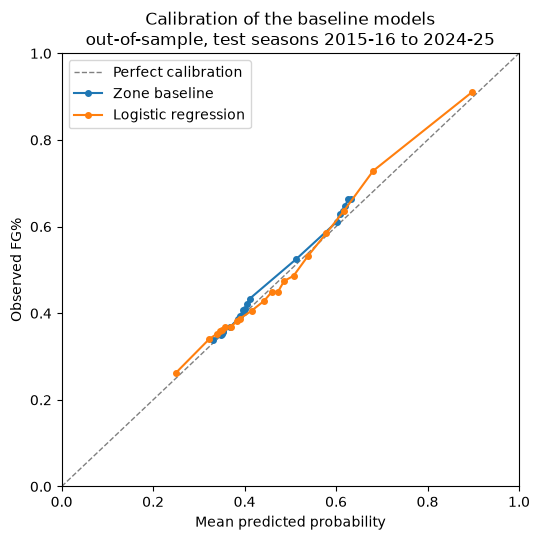

,y,zone,logit,diff_zone,diff_logit
SEASON,,,,,
2015-16,0.452,0.449,0.464,0.003,-0.012
2016-17,0.457,0.448,0.461,0.009,-0.004
2017-18,0.460,0.449,0.466,0.011,-0.006
2018-19,0.461,0.454,0.471,0.006,-0.010
2019-20,0.460,0.453,0.464,0.007,-0.003
2020-21,0.466,0.449,0.454,0.017,0.013
2021-22,0.461,0.449,0.453,0.012,0.008
2022-23,0.475,0.453,0.458,0.022,0.017
2023-24,0.474,0.455,0.458,0.020,0.017


In [17]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="Perfect calibration")
for m, label in [("zone", "Zone baseline"), ("logit", "Logistic regression")]:
    cal = calibration_table(oos["y"], oos[m])
    ax.plot(cal["p_mean"], cal["y_mean"], marker="o", ms=4, label=label)
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed FG%")
ax.set_title("Calibration of the baseline models\nout-of-sample, test seasons 2015-16 to 2024-25")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_calibration_baselines.pdf")
plt.show()

by_season = oos.groupby("SEASON")[["y", "zone", "logit"]].mean()
by_season.assign(diff_zone=by_season["y"] - by_season["zone"], diff_logit=by_season["y"] - by_season["logit"]).round(3)

### 5b. Label drift: why the bias changes sign over time

**What `action_group` is.** Every nba_api shot has an `ACTION_TYPE` label ("Pullup Jump shot", "Driving Layup Shot", ...)
assigned by the NBA, not computed from the shot location. In Stage 2 these labels were grouped into 10
`action_group` values, and the logistic regression learns a separate distance curve for each group.

**What drift means here.** The model assumes that a label means the same kind of shot in every season.
If the way the NBA assigns labels changes, the same label covers a different mix of shots, and a model trained on
old seasons misreads it in new seasons. FG% and share of shots by `action_group` and season:


In [18]:
ag = df.groupby(["SEASON", "action_group"], observed=True)["SHOT_MADE_FLAG"].agg(["mean", "size"]).unstack()
share = ag["size"].div(ag["size"].sum(axis=1), axis=0)
display(ag["mean"].round(3), share.round(3))

action_group,dunk,fadeaway_jumper,floater,hook,jumper,layup,other,pullup_jumper,stepback_jumper,tip_putback
SEASON,,,,,,,,,,
2014-15,0.909,0.484,0.553,0.503,0.337,0.571,0.693,0.571,0.496,0.536
2015-16,0.909,0.452,0.501,0.497,0.328,0.565,0.639,0.540,0.490,0.558
2016-17,0.909,0.472,0.479,0.490,0.333,0.567,0.656,0.523,0.477,0.569
2017-18,0.892,0.424,0.445,0.461,0.358,0.552,NaN,0.432,0.426,0.561
2018-19,0.895,0.417,0.447,0.476,0.352,0.548,NaN,0.410,0.410,0.547
2019-20,0.896,0.408,0.434,0.474,0.358,0.542,NaN,0.406,0.400,0.566
2020-21,0.889,0.431,0.447,0.495,0.369,0.552,NaN,0.411,0.395,0.573
2021-22,0.887,0.406,0.448,0.485,0.359,0.557,NaN,0.397,0.381,0.566
2022-23,0.892,0.429,0.458,0.492,0.370,0.574,NaN,0.397,0.390,0.567


action_group,dunk,fadeaway_jumper,floater,hook,jumper,layup,other,pullup_jumper,stepback_jumper,tip_putback
SEASON,,,,,,,,,,
2014-15,0.047,0.035,0.015,0.038,0.560,0.221,0.006,0.035,0.015,0.027
2015-16,0.049,0.042,0.038,0.037,0.492,0.223,0.005,0.062,0.022,0.030
2016-17,0.051,0.041,0.041,0.037,0.477,0.220,0.004,0.076,0.022,0.030
2017-18,0.053,0.045,0.056,0.037,0.407,0.241,NaN,0.101,0.029,0.032
2018-19,0.058,0.046,0.066,0.039,0.364,0.243,NaN,0.114,0.036,0.035
2019-20,0.059,0.044,0.077,0.030,0.355,0.241,NaN,0.117,0.043,0.035
2020-21,0.054,0.044,0.079,0.029,0.354,0.237,NaN,0.124,0.044,0.035
2021-22,0.058,0.049,0.079,0.029,0.343,0.229,NaN,0.129,0.048,0.036
2022-23,0.060,0.049,0.087,0.031,0.317,0.233,NaN,0.137,0.048,0.038


**Observations.**
- The logistic regression beats the zone baseline in every season: mean log loss 0.642 vs 0.661, Brier 0.226 vs 0.234,
  AUC 0.653 vs 0.625. Distance and shot type carry much more information than the 16 zones.
- Unlike the zone model, its AUC **falls** over time (0.668 in 2015-16, 0.646 in 2024-25) and its mean bias changes sign:
  it over-predicts 2015-19 by up to 1.2 pp and under-predicts 2020-25 by 0.8-1.7 pp.
- The group shares and FG% move a lot: `pullup_jumper` grows from 3.5% of shots (FG 57.1%) in 2014-15 to 13.1%
  (FG 37.6%) in 2024-25, `floater` from 1.5% to 9.5% (55.3% → 44.5%), while plain `jumper` falls from 56.0% to 32.0%
  and its FG% rises from 33.7% to 37.5%. The most likely reading: more difficult off-the-dribble shots are labelled
  "pullup" now, so the remaining "jumpers" are easier shots (e.g. catch-and-shoot).
- Mechanism of the bias: a model trained on old seasons still uses the old meaning of each label. For a 15 ft
  `jumper` it predicts the lower FG% of the old, harder mix, so in recent seasons it is too pessimistic.

**Is it really the labelling and not the style of play?** Share of the raw `ACTION_TYPE` labels per season (in %):


In [19]:
jump_groups = ["jumper", "pullup_jumper", "floater", "other"]
raw = df[df["action_group"].isin(jump_groups)].groupby(["ACTION_TYPE", "SEASON"]).size().unstack(fill_value=0)
raw.div(df.groupby("SEASON").size(), axis=1).mul(100).round(1)


SEASON,2014-15,2015-16,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25
ACTION_TYPE,,,,,,,,,,,
Driving Bank shot,0.2,0.5,0.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Driving Floating Bank Jump Shot,0.0,0.2,0.4,0.9,1.1,1.2,1.1,1.2,1.5,1.5,1.7
Driving Floating Jump Shot,0.0,1.1,1.5,2.4,3.3,4.2,4.3,4.4,5.2,5.0,6.1
Driving Jump shot,0.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Floating Jump shot,1.5,2.5,2.2,2.4,2.2,2.3,2.5,2.2,2.0,1.8,1.7
Jump Bank Shot,0.8,0.9,0.7,0.5,0.4,0.4,0.3,0.3,0.2,0.2,0.2
Jump Shot,52.8,47.5,46.1,39.5,35.3,34.3,34.1,32.7,29.5,28.9,28.7
No Shot,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Pullup Bank shot,0.1,0.1,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Observations.**
- Some labels change abruptly, which a change in playing style cannot do: "Driving Jump shot" is 0.8% of shots in
  2014-15 and 0 afterwards; "Driving Floating Jump Shot" is 0 in 2014-15 and 1.1% in 2015-16 (6.1% in 2024-25);
  all "Bank shot" variants (Driving, Pullup, Running) disappear from 2017-18 on. So the label vocabulary itself changed.
- 2017-18 is also the season in which the NBA switched its tracking provider (SportVU → Second Spectrum); this is only
  a coincidence in time, not a proof of the cause.
- The rise of "Pullup Jump shot" (3.4% → 12%) is gradual, so from these labels alone it could also be a real
  increase of off-the-dribble shooting. The tracking data below separate the two.


**Check against an independent source: tracking pull-ups.** The NBA camera tracking counts pull-up shots
mechanically (jump shots after dribbling, from the player tracking data), independently of the play-by-play
`ACTION_TYPE` label. Team totals per season are downloaded by `scripts/00_data/06_fetch_pullup_tracking.py`.
If the style of play changed, both sources should grow together; if only the labelling changed, the tracking share stays flat.


In [20]:
tracking = pd.read_parquet("../data/raw/tracking/pullup_team.parquet").groupby("SEASON")[["PULL_UP_FGA", "PULL_UP_FGM"]].sum()
n_shots = df.groupby("SEASON").size()
label = df[df["action_group"] == "pullup_jumper"].groupby("SEASON")["SHOT_MADE_FLAG"].agg(["size", "mean"])
pd.DataFrame({"tracking_share": tracking["PULL_UP_FGA"] / n_shots,
              "tracking_fg": tracking["PULL_UP_FGM"] / tracking["PULL_UP_FGA"],
              "label_share": label["size"] / n_shots,
              "label_fg": label["mean"]}).round(3)


,tracking_share,tracking_fg,label_share,label_fg
SEASON,,,,
2014-15,0.239,0.371,0.035,0.571
2015-16,0.249,0.373,0.062,0.540
2016-17,0.252,0.379,0.076,0.523
2017-18,0.256,0.375,0.101,0.432
2018-19,0.258,0.374,0.114,0.410
2019-20,0.260,0.376,0.117,0.406
2020-21,0.261,0.386,0.124,0.411
2021-22,0.264,0.376,0.129,0.397
2022-23,0.255,0.393,0.137,0.397


**Observations.**
- By tracking, pull-ups are a stable 24-26% of all shots in every season, with a stable FG% of 37-39%.
  The playing style (how many shots come off the dribble) hardly changed.
- The `pullup_jumper` label grows from 3.5% to 13% of shots and its FG% falls from 57% to 38%. In 2014-15 only a
  small, easier subset of pull-ups was labelled as such; by 2024-25 the label covers about half of them and its FG%
  matches the tracking FG%.
- This confirms that the drift of `pullup_jumper` (and the opposite drift of plain `jumper`) is a change in the
  labelling, not in how players shoot.


**How certain is the difference?** Change of the pull-up share between 2014-15 and 2024-25 in both sources, with a
95% confidence interval for the difference of two independent proportions (normal approximation):
$\Delta = \hat p_1 - \hat p_0 \pm 1.96 \sqrt{\hat p_0 (1 - \hat p_0) / n_0 + \hat p_1 (1 - \hat p_1) / n_1}$,
where $n$ is the number of all shots in the season.


In [21]:
def share_change(k, n, s0="2014-15", s1="2024-25"):
    p0, p1 = k[s0] / n[s0], k[s1] / n[s1]
    se = np.sqrt(p0 * (1 - p0) / n[s0] + p1 * (1 - p1) / n[s1])
    d = p1 - p0
    return pd.Series({"share_2014_15": p0, "share_2024_25": p1, "diff": d, "ci_low": d - 1.96 * se, "ci_high": d + 1.96 * se})

pd.DataFrame({"tracking": share_change(tracking["PULL_UP_FGA"], n_shots),
              "label": share_change(label["size"], n_shots)}).T.mul(100).round(2)  # in %


,share_2014_15,share_2024_25,diff,ci_low,ci_high
tracking,23.91,23.95,0.04,-0.22,0.29
label,3.49,13.14,9.65,9.49,9.81


**Observations.**
- Tracking: 23.91% → 23.95%, difference +0.04 pp, 95% CI [−0.22; 0.29] pp. The interval contains 0, so there is no
  detectable change in how often players shoot off the dribble.
- Label: 3.49% → 13.14%, difference +9.65 pp, 95% CI [9.49; 9.81] pp, i.e. almost 4 times more shots carry the label.
- Same shots, same seasons, two ways of counting: only the label count moved. This is the quantitative argument
  that the drift comes from the labelling.


## 6. What to do about the drift: sliding window and a model without `action_group`

Two options, tested with the same logistic regression:

- **Drop `action_group`:** one distance curve for all shots (every shot gets the same constant group).
  If the drift made the labels useless, this model would be about as good as the full one.
- **Sliding window:** train only on the last k seasons before the test season (`walk_forward(..., window=k)`),
  so that the model learns the current meaning of the labels and old conventions drop out. k = 1 and k = 3.

`bias` = observed FG% − mean prediction (positive = too pessimistic). The window size is chosen on the same
10 test seasons, so it is a validation choice; the hold-out season 2025-26 is still untouched.


In [22]:
variants = {"logit_w1": dict(window=1, group_col="action_group"),
            "logit_w3": dict(window=3, group_col="action_group"),
            "logit_nogroup": dict(window=None, group_col="no_group")}
X_all = df.assign(no_group="all")

rows = []
for name, v in variants.items():
    for season, tr, te in walk_forward(df["SEASON"], window=v["window"]):
        m = make_logit(group_col=v["group_col"]).fit(X_all[tr], y[tr])
        p = m.predict_proba(X_all[te])[:, 1]
        oos.loc[df.index[te].intersection(oos.index), name] = p
        rows.append({"model": name, "season": season, **evaluate(y[te], p)})

results = pd.concat([results, pd.DataFrame(rows)], ignore_index=True)
models = ["zone", "logit", "logit_w3", "logit_w1", "logit_nogroup"]
bias = oos.groupby("SEASON")[models].mean().rsub(oos.groupby("SEASON")["y"].mean(), axis=0)
display(results.groupby("model")[["log_loss", "brier", "auc"]].mean().loc[models].assign(bias=bias.mean()).round(4))
display(results.pivot(index="season", columns="model", values="auc")[models].round(4), bias.round(3))


,log_loss,brier,auc,bias
model,,,,
zone,0.6610,0.2342,0.6251,0.0123
logit,0.6421,0.2264,0.6529,0.0031
logit_w3,0.6409,0.2258,0.6550,0.0020
logit_w1,0.6402,0.2255,0.6562,0.0007
logit_nogroup,0.6536,0.2308,0.6396,0.0188


model,zone,logit,logit_w3,logit_w1,logit_nogroup
season,,,,,
2015-16,0.6099,0.6678,0.6678,0.6678,0.6314
2016-17,0.6130,0.6634,0.6634,0.6639,0.6308
2017-18,0.6201,0.6446,0.6446,0.6470,0.6370
2018-19,0.6251,0.6569,0.6576,0.6593,0.6428
2019-20,0.6261,0.6568,0.6578,0.6586,0.6440
2020-21,0.6225,0.6452,0.6465,0.6471,0.6347
2021-22,0.6325,0.6479,0.6506,0.6532,0.6417
2022-23,0.6361,0.6521,0.6564,0.6573,0.6468
2023-24,0.6321,0.6483,0.6535,0.6544,0.6433


,zone,logit,logit_w3,logit_w1,logit_nogroup
SEASON,,,,,
2015-16,0.003,-0.012,-0.012,-0.012,0.004
2016-17,0.009,-0.004,-0.004,0.001,0.008
2017-18,0.011,-0.006,-0.006,-0.003,0.025
2018-19,0.006,-0.010,-0.008,-0.006,0.016
2019-20,0.007,-0.003,-0.001,0.004,0.017
2020-21,0.017,0.013,0.017,0.016,0.021
2021-22,0.012,0.008,0.009,-0.002,0.019
2022-23,0.022,0.017,0.014,0.011,0.029
2023-24,0.020,0.017,0.008,0.001,0.026


**Observations.**
- `action_group` is still very useful despite the drift: without it the log loss rises from 0.642 to 0.654
  and the AUC falls from 0.653 to 0.640. So the labels are kept.
- A sliding window helps a little but consistently: 1 season gives log loss 0.6402 vs 0.6421 (expanding),
  AUC 0.656 vs 0.653, and its AUC is higher or equal in every season. 3 seasons is in between.
- It mostly removes the bias: with the expanding window the model is 1.2-1.7 pp too pessimistic in 2022-25,
  with a 1-season window it is within ±0.2 pp in 2023-25. Exception: 2020-21 (+1.6 pp), the season after
  the COVID bubble, where training on 2019-20 alone does not help.
- Conclusion: the drift is mostly a shift of what the labels mean from season to season, and the newest seasons
  describe the test season best. When the model learns from recent seasons, the bias disappears.
- Decision for Stage 4: compare the expanding and a short window (or season weights) also for LightGBM.


## 7. Does the shot angle add anything?

So far the location enters only through the distance and the `is_corner3` flag. `angle_deg` is the angle of the
shot from the hoop (0 = straight on, ±90 = along the baseline, sign = left / right side). It is added as a cubic
B-spline with knots every 15° (`ANGLE_KNOTS`, angles beyond ±90 clipped), one curve shared by all shot types
(`make_logit(angle_knots=...)`). Both models use the 1-season sliding window from section 6.


In [23]:
from xpts.baselines import ANGLE_KNOTS

rows = []
for season, tr, te in walk_forward(df["SEASON"], window=1):
    m = make_logit(angle_knots=ANGLE_KNOTS).fit(df[tr], y[tr])
    p = m.predict_proba(df[te])[:, 1]
    oos.loc[df.index[te].intersection(oos.index), "logit_w1_angle"] = p
    rows.append({"model": "logit_w1_angle", "season": season, **evaluate(y[te], p)})

results = pd.concat([results, pd.DataFrame(rows)], ignore_index=True)
display(results.groupby("model")[["log_loss", "brier", "auc"]].mean().loc[["logit_w1", "logit_w1_angle"]].round(4))
features = m.named_steps["features"]
angle_coef = pd.Series(m.named_steps["logit"].coef_[0], index=features.get_feature_names_out())
angle_coef[angle_coef.index.str.startswith("angle")].round(3).to_frame("weight").T


,log_loss,brier,auc
model,,,
logit_w1,0.6402,0.2255,0.6562
logit_w1_angle,0.6403,0.2255,0.6560


,angle:B1,angle:B2,angle:B3,angle:B4,angle:B5,angle:B6,angle:B7,angle:B8,angle:B9,angle:B10,angle:B11,angle:B12,angle:B13,angle:B14,angle:B15
weight,0.02,0.027,-0.128,-0.037,-0.048,0.009,-0.01,0.086,0.006,0.027,-0.014,0.005,-0.049,0.005,0.078


**Observations.**
- The angle does not help: log loss 0.6403 vs 0.6402, AUC 0.656 in both.
- Its weights are small (|β| < 0.13 on the logit scale) and without a clear pattern between the left and right side.
- So once the distance, the shot type and the corner-3 flag are known, the direction of the shot carries no extra
  information in a linear model. The official zones (`SHOT_ZONE_*`) are a coarse mix of distance and angle,
  so they are not added either. The angle stays in the feature set for LightGBM (Stage 4), which can find
  interactions (e.g. angle x distance) that this model cannot.


## 8. Sensitivity to the spline knots

The distance knots of section 5 were chosen by hand from the court geometry. If the results depended strongly on
this choice, the model would be fragile. The same model (1-season window, no angle) is refitted with uniform knots
every 8, 4, 2 and 1 ft (6 to 41 knots, `make_logit(knots=...)`); more knots = a more flexible distance curve.


In [24]:
from xpts.baselines import DIST_KNOTS

knot_sets = {"geometry (14)": DIST_KNOTS,
             "uniform 8 ft (6)": list(range(0, 41, 8)),
             "uniform 4 ft (11)": list(range(0, 41, 4)),
             "uniform 2 ft (21)": list(range(0, 41, 2)),
             "uniform 1 ft (41)": list(range(0, 41, 1))}

rows = []
for name, knots in knot_sets.items():
    for season, tr, te in walk_forward(df["SEASON"], window=1):
        m = make_logit(knots=knots).fit(df[tr], y[tr])
        rows.append({"knots": name, "season": season, **evaluate(y[te], m.predict_proba(df[te])[:, 1])})

knots_res = pd.DataFrame(rows)
display(knots_res.groupby("knots", sort=False)[["log_loss", "brier", "auc"]].mean().round(4))
knots_res.pivot(index="season", columns="knots", values="log_loss")[list(knot_sets)].round(4)


,log_loss,brier,auc
knots,,,
geometry (14),0.6402,0.2255,0.6562
uniform 8 ft (6),0.6402,0.2255,0.6567
uniform 4 ft (11),0.6401,0.2255,0.6561
uniform 2 ft (21),0.6402,0.2255,0.6559
uniform 1 ft (41),0.6404,0.2256,0.6554


knots,geometry (14),uniform 8 ft (6),uniform 4 ft (11),uniform 2 ft (21),uniform 1 ft (41)
season,,,,,
2015-16,0.6367,0.6368,0.6367,0.6368,0.6371
2016-17,0.6386,0.6388,0.6387,0.6387,0.6387
2017-18,0.6478,0.6446,0.6465,0.6467,0.6477
2018-19,0.6372,0.6375,0.6371,0.6372,0.6374
2019-20,0.6367,0.6368,0.6365,0.6366,0.6368
2020-21,0.6446,0.6451,0.6447,0.6447,0.6450
2021-22,0.6395,0.6398,0.6395,0.6396,0.6398
2022-23,0.6401,0.6405,0.6402,0.6403,0.6403
2023-24,0.6406,0.6409,0.6407,0.6407,0.6407


**Observations.**
- The model is insensitive to the knots: from 6 to 41 knots the mean log loss stays at 0.6401-0.6404, the Brier score
  at 0.2255-0.2256 and the AUC at 0.655-0.657. The differences are much smaller than those between the models above.
- The densest set (1 ft) is very slightly worse, a first sign of overfitting with only one training season; the
  sparsest set (8 ft) is as good as the hand-chosen one. With 0.2 million shots per season the data, not the knots,
  decide the shape of the curve.
- So the hand-chosen geometric knots are kept. Penalised splines (P-splines), which choose the smoothness
  automatically, would not change the results and are not needed.


## 9. Sensitivity to the regularisation: C (logistic regression) and alpha (zone baseline)

The last two hyperparameters were set without checking: the L2 strength of the logistic regression ($C = 1$,
smaller C = stronger penalty) and the smoothing of the zone baseline ($\alpha = 20$ pseudo-shots at the league FG%).
Both are varied over several orders of magnitude, with the same folds as before (logit: 1-season window,
zone: expanding window). If the metrics are flat around the defaults, no tuning is needed.


In [25]:
rows = []
for C_ in [0.001, 0.01, 0.1, 1, 10, 100]:
    for season, tr, te in walk_forward(df["SEASON"], window=1):
        m = make_logit(C=C_).fit(df[tr], y[tr])
        rows.append({"model": "logit", "param": C_, "season": season, **evaluate(y[te], m.predict_proba(df[te])[:, 1])})
for a in [0, 1, 20, 100, 1000, 10000]:
    for season, tr, te in walk_forward(df["SEASON"]):
        m = ZoneBaseline(alpha=a).fit(df[tr], y[tr])
        rows.append({"model": "zone", "param": a, "season": season, **evaluate(y[te], m.predict_proba(df[te])[:, 1])})

reg = pd.DataFrame(rows).groupby(["model", "param"])[["log_loss", "brier", "auc"]].mean()
display(reg.loc["logit"].rename_axis("C").round(5), reg.loc["zone"].rename_axis("alpha").round(5))


,log_loss,brier,auc
C,,,
0.001,0.65246,0.23018,0.65029
0.010,0.64175,0.22597,0.65559
0.100,0.64035,0.22554,0.65611
1.000,0.64023,0.22550,0.65618
10.000,0.64024,0.22551,0.65618
100.000,0.64023,0.22550,0.65618


,log_loss,brier,auc
alpha,,,
0.0,0.66095,0.23422,0.62506
1.0,0.66095,0.23422,0.62506
20.0,0.66095,0.23423,0.62506
100.0,0.66098,0.23423,0.62504
1000.0,0.66126,0.23430,0.62483
10000.0,0.66215,0.23468,0.62344


**Observations.**
- Logistic regression: for C from 0.1 to 100 the log loss is 0.6402-0.6404 and the AUC 0.656; only a very strong
  penalty (C ≤ 0.01) makes the model worse (C = 0.001: log loss 0.652), because it flattens the distance curves.
  With 0.2 million shots and 165 columns the data dominate the penalty, so C = 1 is kept.
- Zone baseline: the results are identical for α from 0 to 100 (log loss 0.6610); only α ≥ 1000 hurts, because every
  zone has thousands of shots and a small α hardly moves its FG%. α = 20 is kept.
- So both defaults lie in the flat region and tuning them would not change the conclusions. The defaults were not
  chosen on these results, so the test seasons are not used for any selection here. Real tuning is needed for
  LightGBM (Stage 4), whose hyperparameters matter much more; it will be done inside each training window.
